# ML-9: CNN for Image Classification (CIFAR-10)

Builds on the neural-network fundamentals from ML-8. A VGG-style CNN with BatchNorm + Dropout is trained on CIFAR-10 with a proper train/val/test split.
It is trained **twice** (without and with data augmentation) to show the effect of augmentation, then evaluated **once** on the untouched test set.

**Run on Colab:** Runtime -> Change runtime type -> T4 GPU, then Runtime -> Run all (about 15 min).

In [11]:
import os, json, copy, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision, torchvision.transforms as T
from torchvision.datasets import CIFAR10

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cpu":
    print("WARNING: no GPU found. Enable one via Runtime -> Change runtime type -> T4 GPU")

os.makedirs("images", exist_ok=True)
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
EPOCHS, BATCH = 30, 128

Device: cuda | torch 2.11.0+cu130


## 1. Data: train / validation / test split

In [12]:
mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
aug_tf   = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize(mean, std)])
plain_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

full_aug   = CIFAR10("./data", train=True,  download=True, transform=aug_tf)
full_plain = CIFAR10("./data", train=True,  download=True, transform=plain_tf)
test_set   = CIFAR10("./data", train=False, download=True, transform=plain_tf)

# 45,000 train / 5,000 validation (fixed seed); the 10,000 test images stay untouched until the end
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

train_aug_dl   = DataLoader(Subset(full_aug,   train_idx), BATCH, shuffle=True,  num_workers=2, pin_memory=True)
train_plain_dl = DataLoader(Subset(full_plain, train_idx), BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_dl         = DataLoader(Subset(full_plain, val_idx),   256,   shuffle=False, num_workers=2, pin_memory=True)
test_dl        = DataLoader(test_set,                      256,   shuffle=False, num_workers=2, pin_memory=True)
print(len(train_idx), "train |", len(val_idx), "val |", len(test_set), "test")

45000 train | 5000 val | 10000 test


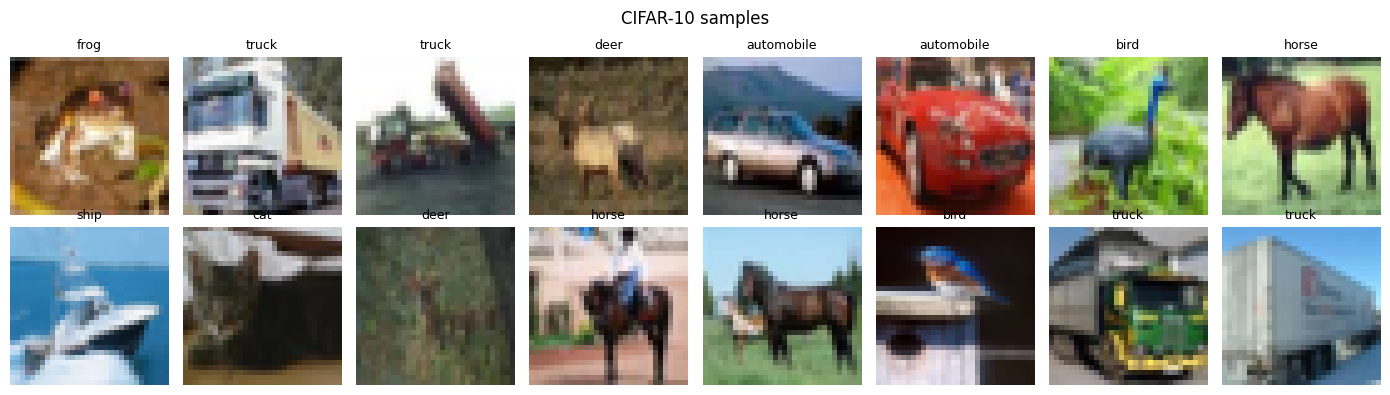

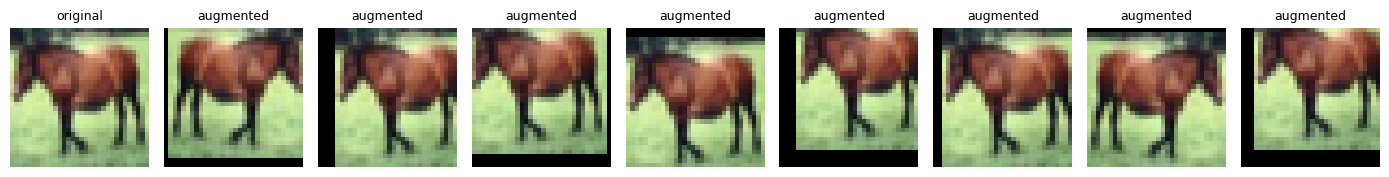

In [13]:
# Sample images
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(full_plain.data[i]); ax.set_title(CLASSES[full_plain.targets[i]], fontsize=9); ax.axis("off")
plt.suptitle("CIFAR-10 samples"); plt.tight_layout(); plt.savefig("images/01_samples.png", dpi=150); plt.show()

# Augmentation examples (same image, random crop + flip)
from PIL import Image
aug_pil = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()])
img = Image.fromarray(full_plain.data[7])
fig, axes = plt.subplots(1, 9, figsize=(14, 2))
axes[0].imshow(img); axes[0].set_title("original", fontsize=9); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(aug_pil(img)); ax.set_title("augmented", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig("images/02_augmentation_examples.png", dpi=150); plt.show()

## 2. CNN architecture (3 conv blocks + fully connected head)

In [14]:
def block(cin, cout, p):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout(p))

class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(block(3, 64, 0.1), block(64, 128, 0.2), block(128, 256, 0.3))  # 32 -> 16 -> 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(256*4*4, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(512, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

print(CNN())
print("Parameters:", sum(p.numel() for p in CNN().parameters()))

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_

## 3. Training utilities (Adam-family optimizer, cross-entropy, per-epoch tracking)

In [15]:
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); loss_sum, correct, n = 0.0, 0, 0
    preds, labels = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=use_amp):
            out = model(x); loss = criterion(out, y)
        loss_sum += loss.item() * y.size(0); n += y.size(0)
        p = out.argmax(1); correct += (p == y).sum().item()
        preds.append(p.cpu()); labels.append(y.cpu())
    return loss_sum / n, correct / n, torch.cat(preds).numpy(), torch.cat(labels).numpy()

def fit(name, train_loader, epochs=EPOCHS):
    torch.manual_seed(SEED)
    model = CNN().to(device).to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, epochs=epochs, steps_per_epoch=len(train_loader))
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = 0.0, None
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); loss_sum, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=use_amp):
                out = model(x); loss = criterion(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            loss_sum += loss.item() * y.size(0); n += y.size(0); correct += (out.argmax(1) == y).sum().item()
        vl, va, _, _ = evaluate(model, val_dl)
        hist["train_loss"].append(loss_sum / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if va > best_acc: best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {ep:02d}/{epochs} | train acc {correct/n:.4f} loss {loss_sum/n:.4f} | "
              f"val acc {va:.4f} loss {vl:.4f} | {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)   # keep the best-on-validation weights (never selected on test)
    return model, hist, best_acc

## 4. Baseline: no augmentation

In [16]:
model_plain, hist_plain, best_val_plain = fit("no-aug", train_plain_dl)

[no-aug] epoch 01/30 | train acc 0.4478 loss 1.5202 | val acc 0.5794 loss 1.2035 | 12s
[no-aug] epoch 02/30 | train acc 0.6251 loss 1.0526 | val acc 0.6572 loss 0.9551 | 8s
[no-aug] epoch 03/30 | train acc 0.7042 loss 0.8427 | val acc 0.7210 loss 0.7845 | 8s
[no-aug] epoch 04/30 | train acc 0.7460 loss 0.7261 | val acc 0.7514 loss 0.6959 | 8s
[no-aug] epoch 05/30 | train acc 0.7766 loss 0.6434 | val acc 0.7332 loss 0.7906 | 8s
[no-aug] epoch 06/30 | train acc 0.7984 loss 0.5819 | val acc 0.7932 loss 0.5815 | 8s
[no-aug] epoch 07/30 | train acc 0.8187 loss 0.5238 | val acc 0.7798 loss 0.6421 | 8s
[no-aug] epoch 08/30 | train acc 0.8364 loss 0.4671 | val acc 0.8214 loss 0.5100 | 8s
[no-aug] epoch 09/30 | train acc 0.8554 loss 0.4159 | val acc 0.8000 loss 0.6302 | 8s
[no-aug] epoch 10/30 | train acc 0.8747 loss 0.3637 | val acc 0.8362 loss 0.4900 | 8s
[no-aug] epoch 11/30 | train acc 0.8863 loss 0.3230 | val acc 0.8588 loss 0.4111 | 8s
[no-aug] epoch 12/30 | train acc 0.9014 loss 0.2807 |

## 5. Same model WITH augmentation (random crop + horizontal flip)

In [17]:
model_aug, hist_aug, best_val_aug = fit("aug", train_aug_dl)

[aug] epoch 01/30 | train acc 0.3851 loss 1.6698 | val acc 0.5346 loss 1.2855 | 11s
[aug] epoch 02/30 | train acc 0.5508 loss 1.2442 | val acc 0.6434 loss 0.9825 | 11s
[aug] epoch 03/30 | train acc 0.6432 loss 1.0062 | val acc 0.6760 loss 0.9404 | 11s
[aug] epoch 04/30 | train acc 0.6945 loss 0.8706 | val acc 0.7144 loss 0.8223 | 11s
[aug] epoch 05/30 | train acc 0.7218 loss 0.7934 | val acc 0.7564 loss 0.7246 | 11s
[aug] epoch 06/30 | train acc 0.7480 loss 0.7194 | val acc 0.7444 loss 0.7460 | 11s
[aug] epoch 07/30 | train acc 0.7669 loss 0.6735 | val acc 0.7432 loss 0.7483 | 11s
[aug] epoch 08/30 | train acc 0.7876 loss 0.6185 | val acc 0.7906 loss 0.6132 | 11s
[aug] epoch 09/30 | train acc 0.8005 loss 0.5805 | val acc 0.8022 loss 0.5891 | 11s
[aug] epoch 10/30 | train acc 0.8173 loss 0.5313 | val acc 0.8304 loss 0.4839 | 11s
[aug] epoch 11/30 | train acc 0.8290 loss 0.4986 | val acc 0.8398 loss 0.4498 | 11s
[aug] epoch 12/30 | train acc 0.8406 loss 0.4668 | val acc 0.8400 loss 0.457

## 6. Training curves & augmentation comparison

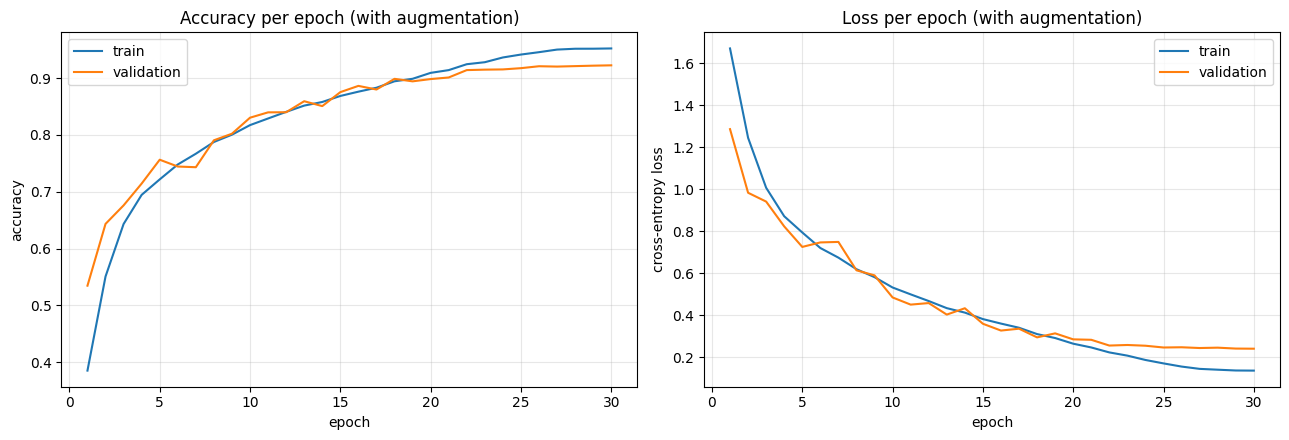

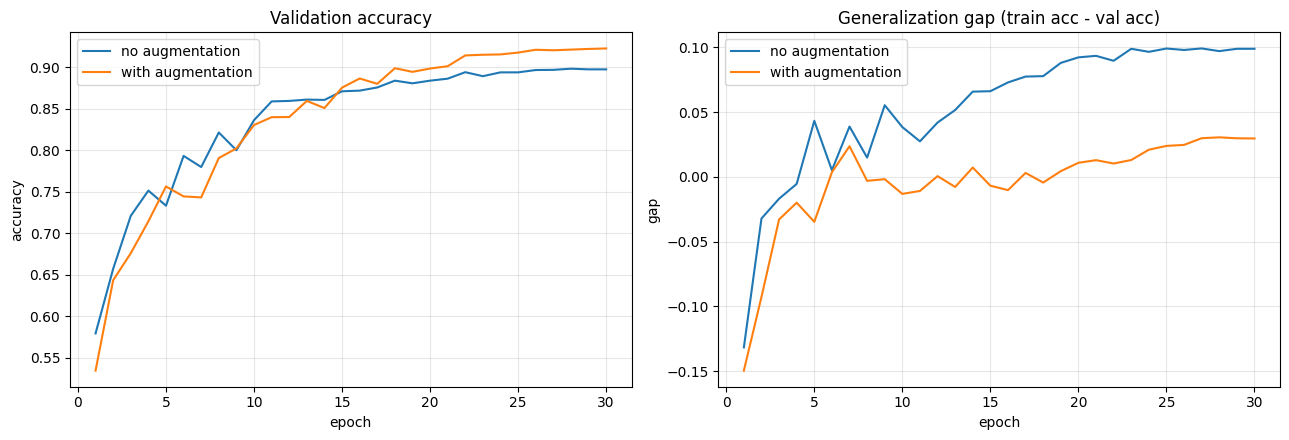

In [18]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ep, hist_aug["train_acc"], label="train"); ax[0].plot(ep, hist_aug["val_acc"], label="validation")
ax[0].set(title="Accuracy per epoch (with augmentation)", xlabel="epoch", ylabel="accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, hist_aug["train_loss"], label="train"); ax[1].plot(ep, hist_aug["val_loss"], label="validation")
ax[1].set(title="Loss per epoch (with augmentation)", xlabel="epoch", ylabel="cross-entropy loss"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("images/03_training_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ep, hist_plain["val_acc"], label="no augmentation"); ax[0].plot(ep, hist_aug["val_acc"], label="with augmentation")
ax[0].set(title="Validation accuracy", xlabel="epoch", ylabel="accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
gap_p = np.array(hist_plain["train_acc"]) - np.array(hist_plain["val_acc"])
gap_a = np.array(hist_aug["train_acc"]) - np.array(hist_aug["val_acc"])
ax[1].plot(ep, gap_p, label="no augmentation"); ax[1].plot(ep, gap_a, label="with augmentation")
ax[1].set(title="Generalization gap (train acc - val acc)", xlabel="epoch", ylabel="gap"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("images/04_augmentation_comparison.png", dpi=150); plt.show()

## 7. Final evaluation on the untouched test set (run once)

In [19]:
_, test_acc_plain, _, _ = evaluate(model_plain, test_dl)
test_loss, test_acc, preds, labels = evaluate(model_aug, test_dl)
print(f"Test accuracy WITHOUT augmentation: {test_acc_plain*100:.2f}%")
print(f"Test accuracy WITH augmentation   : {test_acc*100:.2f}%   (target: >= 85%)")
print("TARGET REACHED" if test_acc >= 0.85 else "Below 85% - see tips in README (more epochs / wider net)")

Test accuracy WITHOUT augmentation: 89.09%
Test accuracy WITH augmentation   : 91.82%   (target: >= 85%)
TARGET REACHED


## 8. Confusion matrix, per-class accuracy, misclassified examples

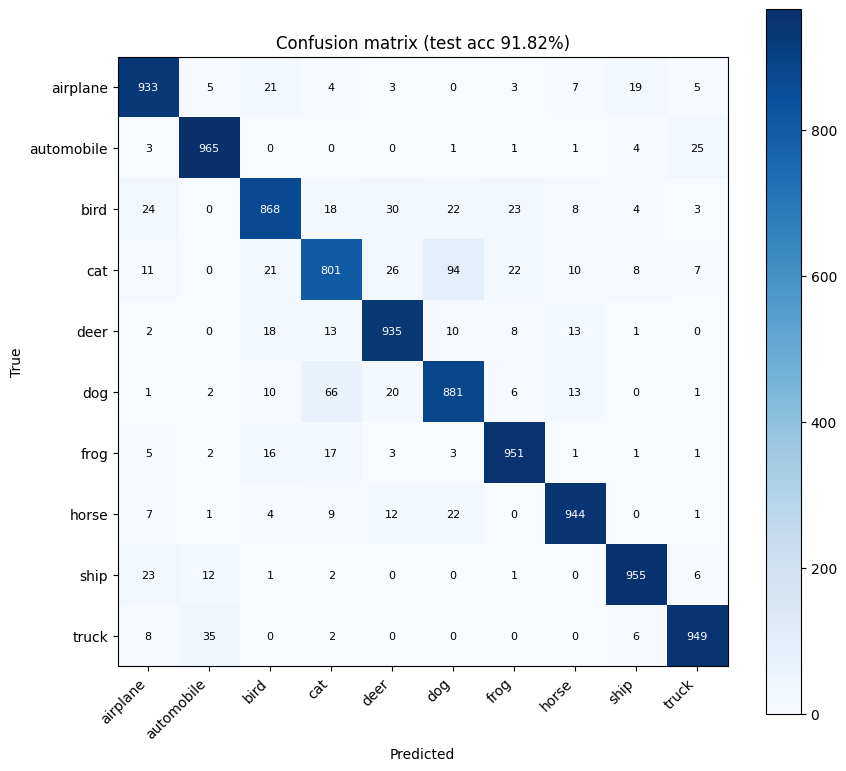

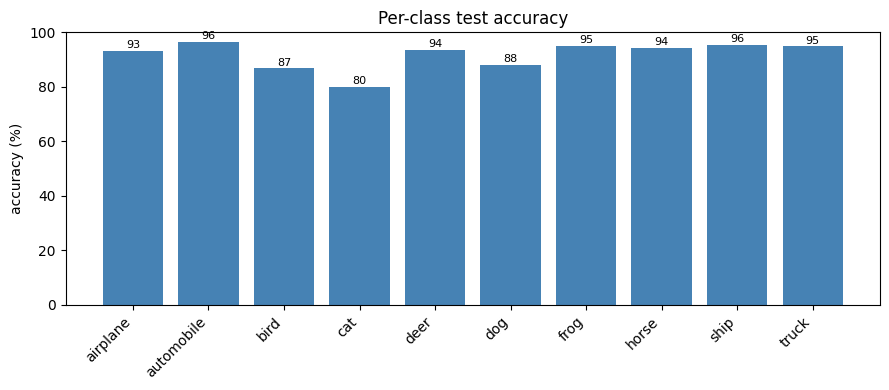

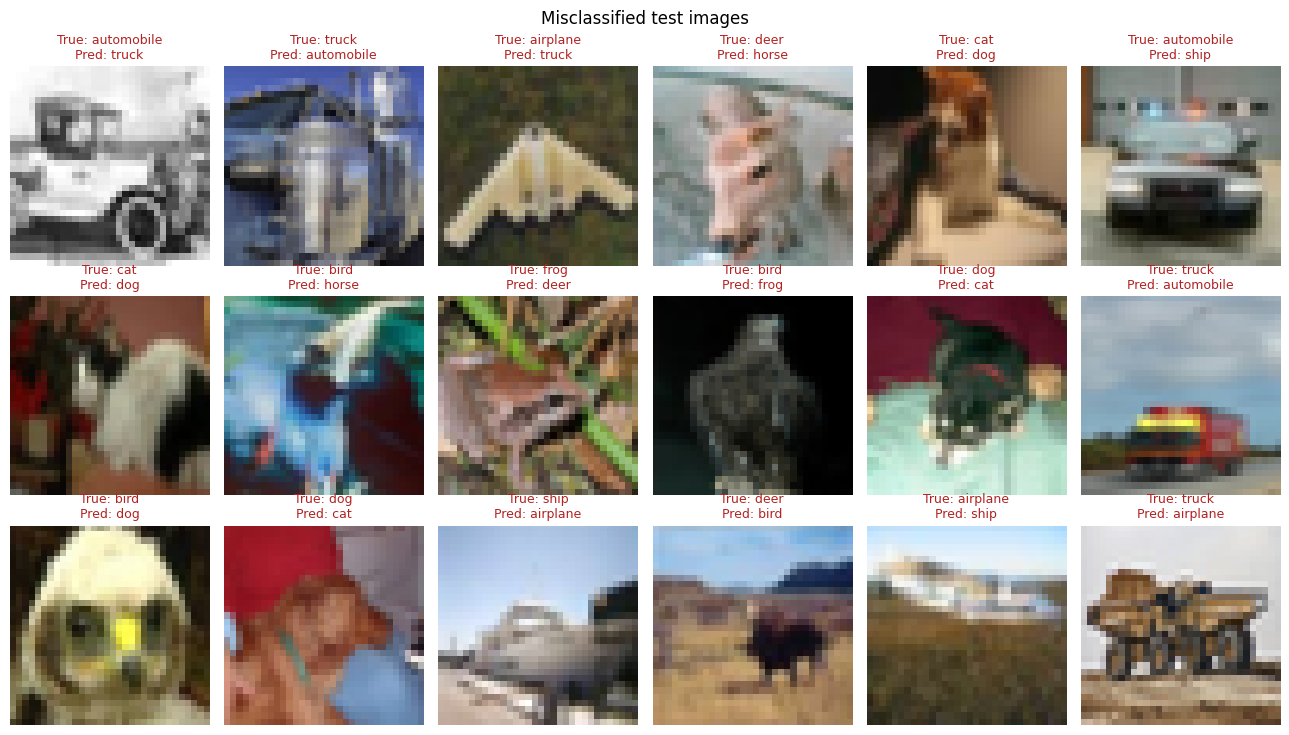

cat predicted as dog: 94 times
dog predicted as cat: 66 times
truck predicted as automobile: 35 times
bird predicted as deer: 30 times
cat predicted as deer: 26 times


In [20]:
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(labels, preds): cm[t, p] += 1

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im)
ax.set(xticks=range(10), yticks=range(10), xlabel="Predicted", ylabel="True", title=f"Confusion matrix (test acc {test_acc*100:.2f}%)")
ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout(); plt.savefig("images/05_confusion_matrix.png", dpi=150); plt.show()

per_class = cm.diagonal() / cm.sum(1)
plt.figure(figsize=(9, 4)); plt.bar(CLASSES, per_class * 100, color="steelblue")
plt.ylim(0, 100); plt.ylabel("accuracy (%)"); plt.title("Per-class test accuracy"); plt.xticks(rotation=45, ha="right")
for i, v in enumerate(per_class): plt.text(i, v*100 + 1, f"{v*100:.0f}", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig("images/06_per_class_accuracy.png", dpi=150); plt.show()

wrong = np.where(preds != labels)[0]
fig, axes = plt.subplots(3, 6, figsize=(13, 7.5))
for ax, i in zip(axes.ravel(), wrong[:18]):
    ax.imshow(test_set.data[i]); ax.axis("off")
    ax.set_title(f"True: {CLASSES[labels[i]]}\nPred: {CLASSES[preds[i]]}", fontsize=9, color="firebrick")
plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.savefig("images/07_misclassified.png", dpi=150); plt.show()

top_pairs = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)[:5]
for n, i, j in top_pairs: print(f"{CLASSES[i]} predicted as {CLASSES[j]}: {n} times")

## 9. Save results + auto-generate README with the real numbers

In [21]:
results = {
    "test_accuracy_with_aug": round(test_acc, 4), "test_accuracy_no_aug": round(test_acc_plain, 4),
    "best_val_acc_with_aug": round(best_val_aug, 4), "best_val_acc_no_aug": round(best_val_plain, 4),
    "epochs": EPOCHS, "batch_size": BATCH, "seed": SEED, "per_class_accuracy": {c: round(float(a), 4) for c, a in zip(CLASSES, per_class)},
}
json.dump(results, open("results.json", "w"), indent=2)

pairs_txt = "; ".join(f"{CLASSES[i]} -> {CLASSES[j]} ({n})" for n, i, j in top_pairs[:3])
best_c, worst_c = CLASSES[int(per_class.argmax())], CLASSES[int(per_class.argmin())]
readme = f"""# ML-9: CNN for Image Classification (CIFAR-10)

A VGG-style Convolutional Neural Network (PyTorch) trained on CIFAR-10, building on the neural-network fundamentals from ML-8.

## Results
| Model | Best val acc | **Test acc** |
|---|---|---|
| CNN, no augmentation | {best_val_plain*100:.2f}% | {test_acc_plain*100:.2f}% |
| CNN + augmentation (final) | {best_val_aug*100:.2f}% | **{test_acc*100:.2f}%** |

Target: >= 85% test accuracy. Test set (10,000 images) was used only once, for the final evaluation. Weights were selected on the validation set.

## Architecture
- 3 conv blocks: [Conv3x3 -> BatchNorm -> ReLU] x2 -> MaxPool -> Dropout (64 -> 128 -> 256 channels, dropout 0.1 / 0.2 / 0.3)
- Fully connected head: Flatten -> Linear(4096, 512) -> BatchNorm -> ReLU -> Dropout(0.5) -> Linear(512, 10)
- Loss: cross-entropy | Optimizer: AdamW (weight decay 5e-4) with OneCycleLR (max lr 2e-3) | {EPOCHS} epochs, batch {BATCH}, mixed precision
- Split: 45,000 train / 5,000 validation / 10,000 test (seed {SEED})
- Augmentation: random crop (padding 4) + random horizontal flip

## Data augmentation
![augmentation](images/02_augmentation_examples.png)
![comparison](images/04_augmentation_comparison.png)

Without augmentation the model reaches {test_acc_plain*100:.2f}% on test; with augmentation {test_acc*100:.2f}% (a change of {(test_acc-test_acc_plain)*100:+.2f} points). The right plot shows how the train-val gap behaves in both runs.

## Training curves
![curves](images/03_training_curves.png)

## Confusion matrix & errors
![cm](images/05_confusion_matrix.png)
![per-class](images/06_per_class_accuracy.png)
![misclassified](images/07_misclassified.png)

Most-confused pairs (true -> predicted): {pairs_txt}. Easiest class: **{best_c}**, hardest: **{worst_c}**. The model tends to confuse visually similar animal classes (e.g. cat/dog), which look alike at 32x32 resolution.

## What got me from the first attempt to 85%+
1. First attempt: plain conv + pooling network without regularization overfit (train acc far above val acc).
2. Added BatchNorm after every conv, which made training faster and more stable.
3. Added Dropout (increasing with depth) to reduce overfitting.
4. Added random crop + flip augmentation, which improved generalization.
5. Used AdamW + OneCycle learning-rate schedule.

## Reproduce
Open `cnn_cifar10.ipynb` in Google Colab (GPU runtime) and run all cells. Numbers are in `results.json`; small run-to-run variation (~0.2-0.5%) is normal on GPU.
"""
open("README.md", "w").write(readme)
print(readme[:600])

# ML-9: CNN for Image Classification (CIFAR-10)

A VGG-style Convolutional Neural Network (PyTorch) trained on CIFAR-10, building on the neural-network fundamentals from ML-8.

## Results
| Model | Best val acc | **Test acc** |
|---|---|---|
| CNN, no augmentation | 89.82% | 89.09% |
| CNN + augmentation (final) | 92.26% | **91.82%** |

Target: >= 85% test accuracy. Test set (10,000 images) was used only once, for the final evaluation. Weights were selected on the validation set.

## Architecture
- 3 conv blocks: [Conv3x3 -> BatchNorm -> ReLU] x2 -> MaxPool -> Dropout (64 -> 128 -> 256 channel


## 10. Download everything for GitHub

In [22]:
!zip -r cifar10_cnn_outputs.zip images results.json README.md
from google.colab import files
files.download("cifar10_cnn_outputs.zip")

  adding: images/ (stored 0%)
  adding: images/06_per_class_accuracy.png (deflated 17%)
  adding: images/02_augmentation_examples.png (deflated 20%)
  adding: images/05_confusion_matrix.png (deflated 14%)
  adding: images/03_training_curves.png (deflated 9%)
  adding: images/07_misclassified.png (deflated 12%)
  adding: images/01_samples.png (deflated 11%)
  adding: images/04_augmentation_comparison.png (deflated 9%)
  adding: results.json (deflated 53%)
  adding: README.md (deflated 45%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>